# Visualisations of the Tracked Regional European Events (OSTIA Observations) using `plotX`

To make the same figures for the basic tracking, open `events_basic.zarr` in place of `events_merged.zarr` below.

In [1]:
from getpass import getuser
from pathlib import Path

import cartopy.crs as ccrs
import dask
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from IPython.display import Video

import marEx
import marEx.helper as hpc

2026-10-11 06:08:37 - marEx - INFO - [PID:2447968] - MarEx logging configured - Level: INFO, Mode: normal


In [2]:
scratch_dir = Path("/scratch") / getuser()[0] / getuser()  # Lustre scratch
out_dir = scratch_dir / "marEx" / "examples" / "regional"  # where notebooks 01 and 02 wrote their output
plot_dir = out_dir / "plots"

movie_period = slice("2020-01-01", "2022-05-31")
example_days = slice("2021-01-01", "2021-01-06")
example_year = slice("2021-01-01", "2021-12-31")

# Movie frames render one per task without threads: 16 single-threaded workers x 7 GB
n_workers, threads_per_worker, memory_limit = 16, 1, "7GB"

In [3]:
plot_dir.mkdir(parents=True, exist_ok=True)

# memory_limit is passed explicitly because on an HPC node Dask sizes workers from the whole node's memory,
# not from the job's allocation, and without it the workers can claim more than the job was granted.
client = hpc.start_local_cluster(
    n_workers=n_workers,
    threads_per_worker=threads_per_worker,
    memory_limit=memory_limit,
    scratch_dir=scratch_dir / "marEx" / "dask",
)

# Records wall time, peak memory, spill and worker restarts for each `monitor.stage(...)` block below
monitor = hpc.ResourceMonitor(client)

2026-10-11 06:08:42 - marEx.helper.cluster - INFO - [PID:2447968] - Starting local Dask cluster with 16 workers, 1 threads each


2026-10-11 06:08:42 - marEx.helper.dask_config - INFO - [PID:2447968] - Configuring Dask for HPC environment


2026-10-11 06:08:42 - marEx.helper.dask_config - INFO - [PID:2447968] - Dask temporary directory: /scratch/b/b382615/marEx/dask/tmpkn2ngg9b


2026-10-11 06:08:42 - marEx.helper.dask_config - INFO - [PID:2447968] - Dask configuration completed


2026-10-11 06:08:42 - marEx.helper.cluster - INFO - [PID:2447968] - System resources: 128 physical cores, 256 logical cores, 251.6GB total memory


...

2026-10-11 06:08:42 - marEx.helper.cluster - INFO - [PID:2447968] - Starting Local cluster startup


2026-10-11 06:08:43 - marEx.helper.cluster - INFO - [PID:2447968] - Completed Local cluster startup in 1.75s


Hostname: l40016
Forward Port: l40016:8787
Dashboard Link: localhost:8787/status
2026-10-11 06:08:43 - marEx.helper.cluster - INFO - [PID:2447968] - Local cluster started successfully - Dashboard: http://127.0.0.1:8787/status


2026-10-11 06:08:43 - marEx.helper.cluster - INFO - [PID:2447968] - After cluster startup - Memory Usage - RSS: 576.0MB, Virtual: 27292.3MB, Percent: 0.2%, Available: 231338.4MB


2026-10-11 06:08:43 - marEx.helper.resources - INFO - [PID:2447968] - Cluster: 16 workers, 16 threads, memory_limit per worker [7.0] GB (112 GB total)


In [4]:
extremes_ds = xr.open_zarr(out_dir / "extremes_shifting_hobday.zarr", chunks={})
extremes_ds

<xarray.Dataset> Size: 50GB
Dimensions:         (time: 9282, lat: 800, lon: 1300, dayofyear: 366)
Coordinates:
  * dayofyear       (dayofyear) uint16 732B 1 2 3 4 5 6 ... 362 363 364 365 366
  * lat             (lat) float32 3kB 30.02 30.08 30.12 ... 69.88 69.93 69.97
  * lon             (lon) float32 5kB -19.98 -19.92 -19.88 ... 44.88 44.92 44.97
  * time            (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-0...
Data variables:
    dat_anomaly     (time, lat, lon) float32 39GB dask.array<chunksize=(25, 800, 1300), meta=np.ndarray>
    extreme_events  (time, lat, lon) bool 10GB dask.array<chunksize=(25, 800, 1300), meta=np.ndarray>
    mask            (lat, lon) bool 1MB dask.array<chunksize=(800, 1300), meta=np.ndarray>
    thresholds      (lat, lon, dayofyear) float32 2GB dask.array<chunksize=(800, 1300, 25), meta=np.ndarray>
Attributes:
    max_anomaly:           21.51153564453125
    method_anomaly:        shifting_baseline
    method_extreme:        seasonal_percentile
    method_percentile:     approximate
    precision:             0.014341023763020834
    preprocessing_steps:   ['Rolling climatology using 15 years', 'Smoothed w...
    smooth_days:           21
    tail:                  upper
    threshold_percentile:  95
    window_days:           11
    window_spatial:        5
    window_years:          15

In [5]:
extreme_events_ds = xr.open_zarr(out_dir / "events_merged.zarr", chunks={})
extreme_events_ds

<xarray.Dataset> Size: 42GB
Dimensions:       (ID: 4552, time: 9282, lat: 800, lon: 1300, component: 2,
                   sibling_ID: 14)
Coordinates:
  * ID            (ID) int32 18kB 1 2 3 4 5 6 ... 4547 4548 4549 4550 4551 4552
  * component     (component) int64 16B 0 1
  * lat           (lat) float32 3kB 30.02 30.08 30.12 ... 69.88 69.93 69.97
  * lon           (lon) float32 5kB -19.98 -19.92 -19.88 ... 44.88 44.92 44.97
  * time          (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-05-...
Dimensions without coordinates: sibling_ID
Data variables:
    ID_field      (time, lat, lon) int32 39GB dask.array<chunksize=(1, 800, 1300), meta=np.ndarray>
    area          (time, ID) float32 169MB dask.array<chunksize=(1, 4552), meta=np.ndarray>
    centroid      (component, time, ID) float32 338MB dask.array<chunksize=(1, 1, 4552), meta=np.ndarray>
    global_ID     (time, ID) int32 169MB dask.array<chunksize=(1, 4552), meta=np.ndarray>
    merge_ledger  (time, ID, sibling_ID) int32 2GB dask.array<chunksize=(1, 4552, 14), meta=np.ndarray>
    presence      (time, ID) bool 42MB dask.array<chunksize=(1, 4552), meta=np.ndarray>
    time_end      (ID) datetime64[ns] 36kB dask.array<chunksize=(4552,), meta=np.ndarray>
    time_start    (ID) datetime64[ns] 36kB dask.array<chunksize=(4552,), meta=np.ndarray>
Attributes: (12/14)
    N_events_final:              4552
    N_objects_filtered:          34736
    N_objects_prefiltered:       43719
    R_fill:                      16
    T_fill:                      4
    accepted_area_fraction:      0.9964706962724902
    ...                          ...
    area_threshold (cells):      600
    multi_parent_merges:         3101
    nn_partitioning:             1
    overlap_threshold:           0.25
    preprocessed_area_fraction:  0.6987502028915848
    total_merges:                7466

In [6]:
# Extract the Events ID Field
ID_field = extreme_events_ds.ID_field
ID_field

<xarray.DataArray 'ID_field' (time: 9282, lat: 800, lon: 1300)> Size: 39GB
dask.array<open_dataset-ID_field, shape=(9282, 800, 1300), dtype=int32, chunksize=(1, 800, 1300), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float32 3kB 30.02 30.08 30.12 30.17 ... 69.88 69.93 69.97
  * lon      (lon) float32 5kB -19.98 -19.92 -19.88 -19.83 ... 44.88 44.92 44.97
  * time     (time) datetime64[ns] 74kB 1997-01-01T12:00:00 ... 2022-05-31T12...

## Make a Movie using `plotX.animate`

`animate()` renders one frame per task and cannot use threads, which is why this notebook's cluster runs one thread per
worker. Each movie is written to `plot_dir`, and the copy shown here is the same file, kept in the repository's
`media/` folder. See [Animation](https://marex.readthedocs.io/en/latest/guide/visualisation.html#animations).

In [7]:
with monitor.stage("Movie: event IDs"):
    # Choose a subset of the ID field
    extreme_events_ds_subset = extreme_events_ds.sel(time=movie_period)
    ID_field_subset = extreme_events_ds_subset.ID_field
    centroids_subset = extreme_events_ds_subset.centroid

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
    ID_field_subset.plotX.animate(config, plot_dir=plot_dir, file_name="movie_ID_field_regional", centroids=centroids_subset)

2026-10-11 06:09:03 - marEx - INFO - [PID:2448202] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448230] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448235] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448211] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448219] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448205] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448247] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448228] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448260] - MarEx logging configured - Level: INFO, Mode: normal
2026-10-11 06:09:03 - marEx - INFO - [PID:2448

2026-10-11 06:09:04 - marEx - INFO - [PID:2448253] - MarEx logging configured - Level: INFO, Mode: normal


ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

Input #0, image2, from '/scratch/b/b382615/marEx/dask/tmpkn2ngg9b/marex_animate_lqxsuqob/time_%04d.jpg':
  Duration: 00:01:28.20, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: mjpeg (Baseline), yuvj420p(pc, bt470bg/unknown/unknown), 2100x1300 [SAR 300:300 DAR 21:13], 10 fps, 10 tbr, 10 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (mjpeg (native) -> h264 (libx264))
Press [q] to stop, [?] for help
[swscaler @ 0x7fffe8014d00] deprecated pixel format used, make sure you did set range correctly


    Last message repeated 3 times
[libx264 @ 0x688ee40] using SAR=1/1
[libx264 @ 0x688ee40] using cpu capabilities: MMX2 SSE2Fast SSSE3 SSE4.2 AVX FMA3 BMI2 AVX2
[libx264 @ 0x688ee40] profile High, level 5.0, 4:2:0, 8-bit
[libx264 @ 0x688ee40] 264 - core 164 r3191 4613ac3 - H.264/MPEG-4 AVC codec - Copyleft 2003-2024 - http://www.videolan.org/x264.html - options: cabac=1 ref=2 deblock=1:0:0 analyse=0x3:0x113 me=hex subme=6 psy=1 psy_rd=1.00:0.00 mixed_ref=1 me_range=16 chroma_me=1 trellis=1 8x8dct=1 cqm=0 deadzone=21,11 fast_pskip=1 chroma_qp_offset=-2 threads=41 lookahead_threads=6 sliced_threads=0 nr=0 decimate=1 interlaced=0 bluray_compat=0 constrained_intra=0 bframes=3 b_pyramid=2 b_adapt=1 b_bias=0 direct=1 weightb=1 open_gop=0 weightp=1 keyint=250 keyint_min=10 scenecut=40 intra_refresh=0 rc_lookahead=30 rc=crf mbtree=1 crf=22.0 qcomp=0.60 qpmin=0 qpmax=69 qpstep=4 ip_ratio=1.40 aq=1:1.00
Output #0, mp4, to '/scratch/b/b382615/marEx/examples/regional/plots/movie_ID_field_regional

[mp4 @ 0x6894e40] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:3460KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.322512%
frame=  882 fps=165 q=-1.0 Lsize=    3471KiB time=00:01:28.00 bitrate= 323.1kbits/s speed=16.4x    
[libx264 @ 0x688ee40] frame I:4     Avg QP: 9.83  size:137591
[libx264 @ 0x688ee40] frame P:231   Avg QP:20.06  size:  7253
[libx264 @ 0x688ee40] frame B:647   Avg QP:21.96  size:  2035
[libx264 @ 0x688ee40] consecutive B-frames:  1.1%  1.8%  4.1% 93.0%
[libx264 @ 0x688ee40] mb I  I16..4: 46.8% 38.4% 14.7%
[libx264 @ 0x688ee40] mb P  I16..4:  0.2%  0.6%  0.4%  P16..4:  0.7%  0.3%  0.2%  0.0%  0.0%    skip:97.6%
[libx264 @ 0x688ee40] mb B  I16..4:  0.1%  0.0%  0.1%  B16..8:  0.8%  0.3%  0.1%  direct: 0.1%  skip:98.5%  L0:50.0% L1:46.1% BI: 3.8%
[libx264 @ 0x688ee40] 8x8 transform intra:37.2% inter:17.5%
[libx264 @ 0x688ee40] coded y,uvDC,uvAC intra: 23.8% 23.9% 20.4% inter:

Movie: event IDs: 1.4 min, peak worker memory 11.8 GB of 112 GB, client 0.8 GB, spilled 0.0 GB, restarts 0


In [8]:
Video("../../media/movie_ID_field_regional.mp4", width=640, height=480, embed=False)

In [9]:
with monitor.stage("Movie: anomaly"):
    # Plot the anomalous temperature field

    anomaly_subset = extremes_ds.dat_anomaly.sel(time=movie_period)
    anomaly_hot = anomaly_subset.where(anomaly_subset > 0, 0)

    extreme_events_ds_subset = extreme_events_ds.sel(time=movie_period)
    ID_field_subset = extreme_events_ds_subset.ID_field
    centroids_subset = extreme_events_ds_subset.centroid

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(var_units="Temperature Anomaly", cmap="inferno", cperc=[0, 98], projection=ccrs.PlateCarree())
    anomaly_hot.plotX.animate(
        config, plot_dir=plot_dir, file_name="movie_anomaly_regional", centroids=centroids_subset, object_ids=ID_field_subset
    )

ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

Input #0, image2, from '/scratch/b/b382615/marEx/dask/tmpkn2ngg9b/marex_animate_jdz7yq1d/time_%04d.jpg':
  Duration: 00:01:28.20, start: 0.000000, bitrate: N/A
  Stream #0:0: Video: mjpeg (Baseline), yuvj420p(pc, bt470bg/unknown/unknown), 2100x1040 [SAR 300:300 DAR 105:52], 10 fps, 10 tbr, 10 tbn
Stream mapping:
  Stream #0:0 -> #0:0 (mjpeg (native) -> h264 (libx264))
Press [q] to stop, [?] for help
[swscaler @ 0x7fffe8014d00] deprecated pixel format used, make sure you did set range correctly
    Last message repeated 3 times
[libx264 @ 0x688f380] using SAR=1/1
[libx264 @ 0x688f380] using cpu capabilities: MMX2 SSE2Fast SSSE3 SSE4.2 AVX FMA3 BMI2 AVX2
[libx264 @ 0x688f380] profile High, level 4.2, 4:2:0, 8-bit
[libx264 @ 0x688f380] 264 - core 164 r3191 4613ac3 - H.264/MPEG-4 AVC codec - Copyleft 2003-2024 - http://www.videolan.org/x264.html - options: cabac=1 ref=2 deblock=1:0:0 analyse=0x3:0x113 me=hex subme=6 psy=1 psy_rd=1.00:0.00 mixed_ref=1 me_range=16 chroma_me=1 trellis=1 8x8dc

[mp4 @ 0x6886c80] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:34511KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.033883%
frame=  882 fps=186 q=-1.0 Lsize=   34522KiB time=00:01:28.00 bitrate=3213.7kbits/s speed=18.5x    
[libx264 @ 0x688f380] frame I:4     Avg QP:10.58  size:140916
[libx264 @ 0x688f380] frame P:222   Avg QP:20.69  size: 63118
[libx264 @ 0x688f380] frame B:656   Avg QP:24.88  size: 31650
[libx264 @ 0x688f380] consecutive B-frames:  0.8%  0.0%  0.3% 98.9%
[libx264 @ 0x688f380] mb I  I16..4: 50.0% 37.1% 12.9%
[libx264 @ 0x688f380] mb P  I16..4:  0.7%  8.7%  2.1%  P16..4:  5.2%  3.0%  2.6%  0.0%  0.0%    skip:77.8%
[libx264 @ 0x688f380] mb B  I16..4:  0.6%  1.0%  2.3%  B16..8:  4.6%  4.1%  2.5%  direct: 4.1%  skip:80.8%  L0:43.1% L1:40.7% BI:16.2%
[libx264 @ 0x688f380] 8x8 transform intra:49.2% inter:47.9%
[libx264 @ 0x688f380] coded y,uvDC,uvAC intra: 73.4% 81.7% 78.2% inter

Movie: anomaly: 4.4 min, peak worker memory 15.5 GB of 112 GB, client 0.9 GB, spilled 0.0 GB, restarts 0


In [10]:
Video("../../media/movie_anomaly_regional.mp4", width=640, height=480, embed=False)

The same period from the basic tracking, with no temporal gap filling, no merging or splitting, and no independent tracking of the parts of a merged event.

In [11]:
with monitor.stage("Movie: basic tracking IDs"):
    # Basic-tracking IDs over the movie period
    ID_field_basic_subset = xr.open_zarr(out_dir / "events_basic.zarr", chunks={}).ID_field.sel(time=movie_period)

    # Setup Plotting Configuration & Animate
    config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
    ID_field_basic_subset.plotX.animate(config, plot_dir=plot_dir, file_name="movie_ID_field_basic_regional")

ffmpeg version 7.0.2-static https://johnvansickle.com/ffmpeg/  Copyright (c) 2000-2024 the FFmpeg developers
  built with gcc 8 (Debian 8.3.0-6)
  configuration: --enable-gpl --enable-version3 --enable-static --disable-debug --disable-ffplay --disable-indev=sndio --disable-outdev=sndio --cc=gcc --enable-fontconfig --enable-frei0r --enable-gnutls --enable-gmp --enable-libgme --enable-gray --enable-libaom --enable-libfribidi --enable-libass --enable-libvmaf --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-librubberband --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libvorbis --enable-libopus --enable-libtheora --enable-libvidstab --enable-libvo-amrwbenc --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libdav1d --enable-libxvid --enable-libzvbi --enable-libzimg
  libavutil      59.  8.100 / 59.  8.100
  libavcodec     61.  3.100 / 61.  3.100
  libavformat   

[mp4 @ 0x6894e40] Starting second pass: moving the moov atom to the beginning of the file
[out#0/mp4 @ 0x6883100] video:3513KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.315148%
frame=  882 fps=188 q=-1.0 Lsize=    3524KiB time=00:01:28.00 bitrate= 328.1kbits/s speed=18.8x    
[libx264 @ 0x688ee40] frame I:4     Avg QP: 9.96  size:136511
[libx264 @ 0x688ee40] frame P:235   Avg QP:20.19  size:  5905
[libx264 @ 0x688ee40] frame B:643   Avg QP:22.34  size:  2587
[libx264 @ 0x688ee40] consecutive B-frames:  1.1%  2.5%  7.5% 88.9%
[libx264 @ 0x688ee40] mb I  I16..4: 45.6% 39.7% 14.7%
[libx264 @ 0x688ee40] mb P  I16..4:  0.2%  0.6%  0.4%  P16..4:  0.8%  0.2%  0.2%  0.0%  0.0%    skip:97.6%
[libx264 @ 0x688ee40] mb B  I16..4:  0.2%  0.0%  0.1%  B16..8:  0.8%  0.3%  0.2%  direct: 0.1%  skip:98.3%  L0:50.8% L1:45.9% BI: 3.3%
[libx264 @ 0x688ee40] 8x8 transform intra:36.9% inter:13.4%
[libx264 @ 0x688ee40] coded y,uvDC,uvAC intra: 22.4% 24.4% 20.6% inter:

Movie: basic tracking IDs: 1.1 min, peak worker memory 14.8 GB of 112 GB, client 0.9 GB, spilled 0.0 GB, restarts 0


In [12]:
Video("../../media/movie_ID_field_basic_regional.mp4", width=640, height=480, embed=False)

## Plot Consecutive Days of Extreme Events

2026-10-11 06:15:40 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:15:40 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 0.26s


2026-10-11 06:15:40 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:15:40 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 0.24s


2026-10-11 06:15:40 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


...

2026-10-11 06:15:41 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 0.22s


2026-10-11 06:15:41 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:15:41 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 0.23s


2026-10-11 06:15:41 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:15:41 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 0.23s


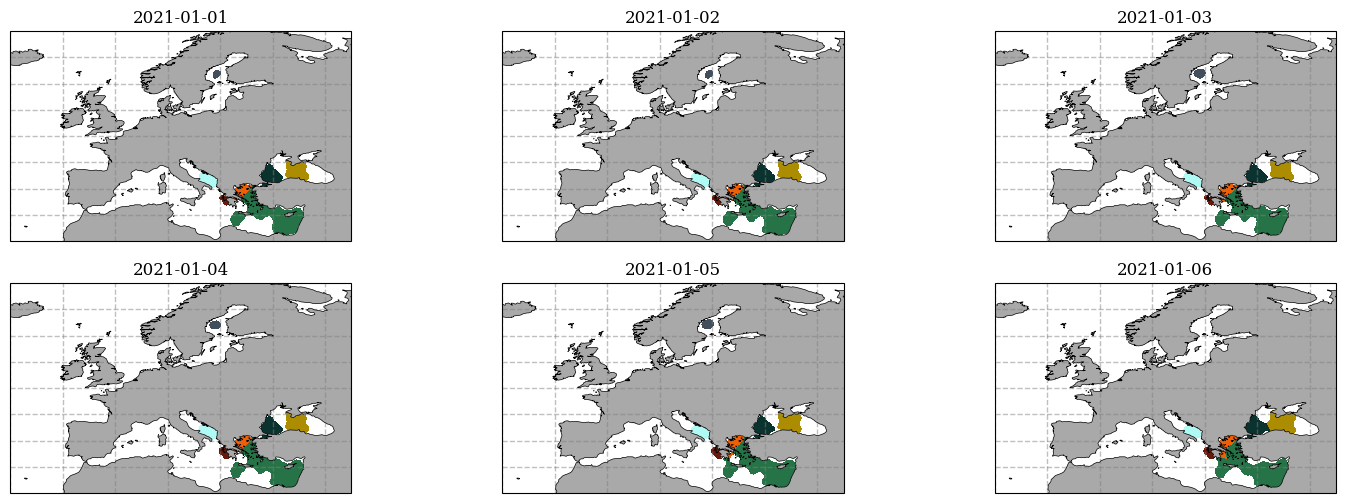

In [13]:
# Choose a subset of the ID field
ID_field_subset = ID_field.sel(time=example_days)

# Setup Plotting Configuration
config = marEx.PlotConfig(plot_IDs=True, projection=ccrs.PlateCarree())
fig, ax = ID_field_subset.plotX.multi_plot(config, col="time", col_wrap=3);

## Plot Regional Extreme Event Frequency

2026-10-11 06:16:11 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:16:34 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 22.48s


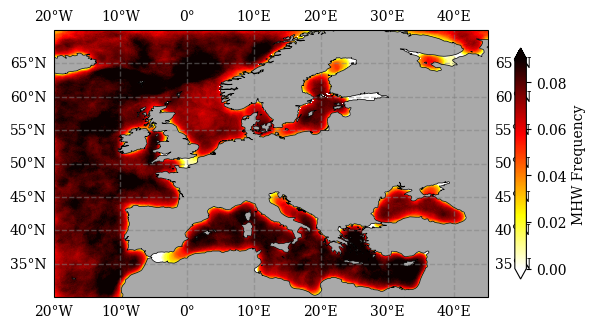

In [14]:
# Calculate the frequency of Event Occurrence
event_frequency = (ID_field > 0).mean("time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True, projection=ccrs.PlateCarree())
fig, ax, im = event_frequency.plotX.single_plot(config)

## Plot Seasonal Extreme Event Frequency

2026-10-11 06:19:08 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:19:47 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 38.89s


2026-10-11 06:19:47 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:20:26 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 38.80s


2026-10-11 06:20:26 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:21:06 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 40.30s


2026-10-11 06:21:06 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:21:45 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 39.14s


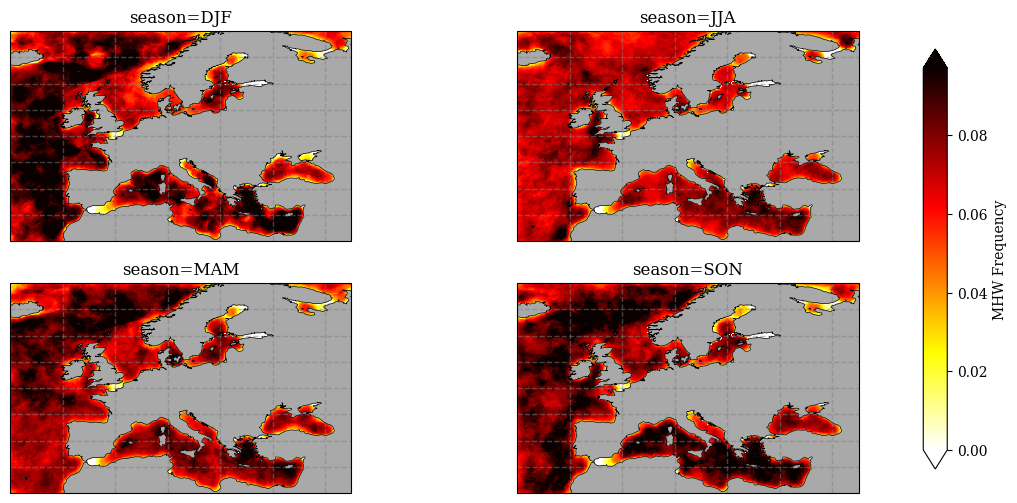

In [15]:
# Calculate the frequency of Event Occurrence per season
seasonal_frequency = (ID_field > 0).groupby("time.season").mean(dim="time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="MHW Frequency", cmap="hot_r", cperc=[0, 96], grid_labels=True, projection=ccrs.PlateCarree())
fig, ax = seasonal_frequency.plotX.multi_plot(config, col="season", col_wrap=2);

## Find & Plot a Few of the Longest Regional Events

In [16]:
events_duration = extreme_events_ds.time_end - extreme_events_ds.time_start
longest_events = events_duration.sortby(events_duration, ascending=False).ID

for ID in longest_events[:10].values:
    print(
        f"ID: {ID:<6}   Start Day: {extreme_events_ds.time_start.sel(ID=ID).dt.strftime('%Y-%m-%d').values}  -->  Duration: {events_duration.sel(ID=ID).dt.days.values:<4} days"
    )

ID: 1400     Start Day: 2004-01-10  -->  Duration: 311  days
ID: 147      Start Day: 1997-09-22  -->  Duration: 198  days
ID: 146      Start Day: 1997-09-19  -->  Duration: 195  days
ID: 149      Start Day: 1997-09-29  -->  Duration: 192  days


ID: 1170     Start Day: 2002-11-25  -->  Duration: 185  days
ID: 3542     Start Day: 2016-02-28  -->  Duration: 184  days
ID: 1164     Start Day: 2002-11-19  -->  Duration: 180  days
ID: 4282     Start Day: 2020-09-05  -->  Duration: 176  days
ID: 1175     Start Day: 2002-12-03  -->  Duration: 175  days


ID: 316      Start Day: 1998-09-17  -->  Duration: 174  days


2026-10-11 06:23:42 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:25:39 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 117.53s


2026-10-11 06:25:39 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:27:36 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 116.74s


2026-10-11 06:27:36 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


...

2026-10-11 06:37:35 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 122.38s


2026-10-11 06:37:35 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:39:36 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 120.84s


2026-10-11 06:39:36 - marEx.plotX.gridded - INFO - [PID:2447968] - Starting Gridded plot rendering


2026-10-11 06:41:37 - marEx.plotX.gridded - INFO - [PID:2447968] - Completed Gridded plot rendering in 120.63s


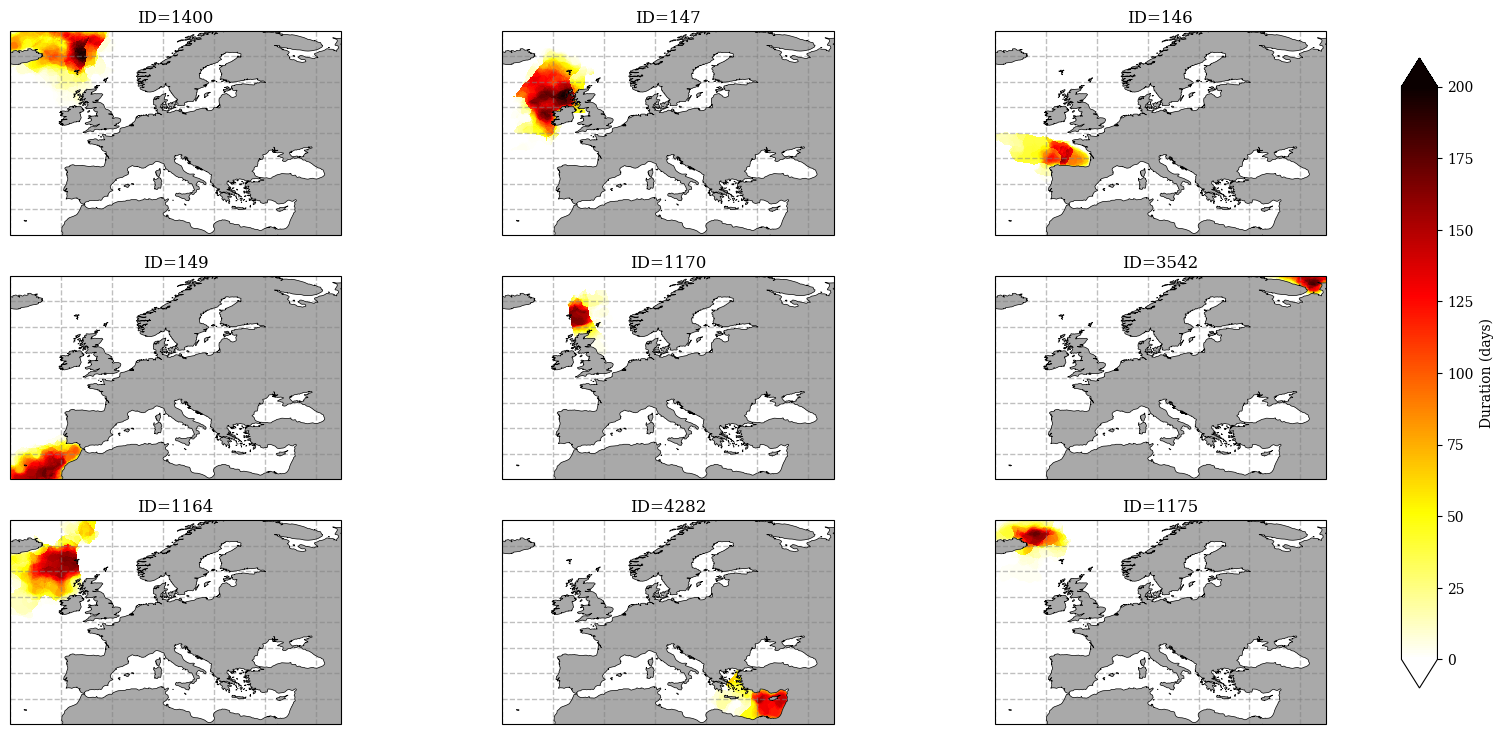

In [17]:
# Calculate the local duration of the longest events
long_events = ID_field == (longest_events[:9]).chunk({"ID": 1})
long_events_local_duration = (long_events > 0).sum("time")

# Setup Plotting Configuration
config = marEx.PlotConfig(var_units="Duration (days)", cmap="hot_r", cperc=[0, 100], projection=ccrs.PlateCarree())
fig, ax = long_events_local_duration.plotX.multi_plot(config, col="ID", col_wrap=3);

## ID Maximum and Mean Event Area

In [18]:
areas_max = extreme_events_ds.area.max().compute()
print(f"Maximum object area: {areas_max.values:.0f} km²")

areas_mean = extreme_events_ds.area.mean().compute()
print(f"Mean object area: {areas_mean.values:.0f} km²")

Maximum object area: 1651347 km²


Mean object area: 136922 km²


## Wall Time and Memory

One row per stage, measured while the notebook ran on the cluster configured at the top. Peak worker memory is the
summed process memory the workers report to the scheduler, which is the quantity Dask compares against `memory_limit`.
The client (this kernel) is counted separately.

In [19]:
monitor.summary()

,wall (min),peak worker memory (GB),peak client memory (GB),peak spilled to disk (GB),worker restarts
stage,,,,,
Movie: event IDs,1.43,11.81,0.81,0.0,0
Movie: anomaly,4.39,15.47,0.90,0.0,0
Movie: basic tracking IDs,1.10,14.80,0.90,0.0,0
total,6.92,15.47,0.90,0.0,0


In [20]:
client.close()